# TP 1: Get familiar with Keras and PyTorch, Multi-Layer Perceptron (MLP) and Convolutional Neural Network (CNN)

## Objective of the following tutorial: Implement a MLP and a CNN on CIFAR-10 data

Help:
- https://pytorch.org/tutorials/beginner/basics/intro.html
- https://pytorch.org/tutorials/beginner/deep_learning_60min_blitz.html


- [PyTorch official website](https://pytorch.org/)
- [PyTorch Lightning](https://www.pytorchlightning.ai/)

## Package check

PyTorch is a deep learning framework that provides tools for: tensor computation, automatic differentiation, neural network computation, optimization, GPU acceleration, etc

In [1]:
import scipy
import numpy as np # manipulate N-dimensional arrays
import pandas as pd # data frame
import matplotlib.pyplot as plt # data plotting
import seaborn # advanced data plotting
from sklearn import preprocessing # basic ML models
# import scipy # scientific computing library

import os

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms

Check environment:

In [2]:
print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

PyTorch version: 2.7.1+cu118
CUDA available: True


Define device:

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


# CIFAR-10 dataset

## a) Load the data

The data can be directly downloaded with PyTorch. Please visit the following website: https://pytorch.org/vision/stable/datasets.html

In [4]:
# # With data images, the preprocess must be declared before loading the data
# For the moment, we just convert to Tensor type

transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

If the download of the data takes too much time, download the data manually [here](https://www.google.com/url?sa=i&source=web&rct=j&url=https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz&ved=2ahUKEwjg-rr14oGXAxUeOfsDHbVJL7QQy_kOeggIAggACBwQAg&opi=89978449&cd&psig=AOvVaw1dVj7ZdiiBFhFiE_10HIqO&ust=1790152242765000) and place the compressed file in a data folder.

How many samples and classes in the datasets ? 

In [5]:
from collections import Counter

In [6]:
print(len(train_dataset), len(test_dataset))
print(train_dataset.classes)
print(train_dataset.class_to_idx)
print(Counter(train_dataset.targets))
print(Counter(test_dataset.targets))

50000 10000
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
{'airplane': 0, 'automobile': 1, 'bird': 2, 'cat': 3, 'deer': 4, 'dog': 5, 'frog': 6, 'horse': 7, 'ship': 8, 'truck': 9}
Counter({6: 5000, 9: 5000, 4: 5000, 1: 5000, 2: 5000, 7: 5000, 8: 5000, 3: 5000, 5: 5000, 0: 5000})
Counter({3: 1000, 8: 1000, 0: 1000, 6: 1000, 1: 1000, 9: 1000, 5: 1000, 7: 1000, 4: 1000, 2: 1000})


Dimension and type of the data ?

In [7]:
print(type(train_dataset[0]))
print(train_dataset[0][0].shape)
print(type(train_dataset[0][0]))
print(train_dataset[0][1])
print(type(train_dataset[0][1]))

<class 'tuple'>
torch.Size([3, 32, 32])
<class 'torch.Tensor'>
6
<class 'int'>


## b) Preprocess the data

Split the training set into a train and validation set.
Have a look on https://pytorch.org/docs/stable/data.html. <br>
You can easily create your own dataset.

In [8]:
from sklearn.model_selection import train_test_split
random_state = 42 #for reproductible results

# Split by generating train and val index with train_test_split() 
# Be cautious and keep the proportions of the original dataset
train_indices, val_indices = train_test_split(
    np.arange(len(train_dataset)),
    test_size=0.2,
    random_state=42,
    stratify=np.array(train_dataset.targets)
)

In [11]:
# Convert to Dataset objects
trainset = torch.utils.data.Subset(train_dataset, train_indices)
valset = torch.utils.data.Subset(train_dataset, val_indices)

(Optional) Another possibility is to use the random_split but the proportions will not be kept. Note that the more samples you use, the lower the likelihood of creating an imbalance.

In [10]:
trainset, valset = torch.utils.data.random_split(...)

TypeError: random_split() missing 1 required positional argument: 'lengths'

Only once you have your 3 Datsets (train, val, test), you can use the dataloader that will split each dataset into batches. 

Here, with Pytorch, we can custom our dataloaders especially to optimize training time using arguments like `num_workers`, `prefetch_factor`...etc. See the documentation: https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader

In [12]:
batch_size = 32 # You can start with 32
train_loader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = torch.utils.data.DataLoader(
    valset,
    batch_size=batch_size,
    shuffle=True
)
test_loader = torch.utils.data.DataLoader(
    test_dataset, 
    batch_size=batch_size,
    shuffle=True
)

What does the DataLoaders contain ? Print the dimension of each element:

In [13]:
for elm in train_loader:
    print(type(elm))
    print(elm[0].shape)
    print(type(elm[0]))
    print(elm[1].shape)
    print(type(elm[1]))
    break

<class 'list'>
torch.Size([32, 3, 32, 32])
<class 'torch.Tensor'>
torch.Size([32])
<class 'torch.Tensor'>


## c) Visualize the data

Vizualize a grid of images <br>
Help: https://pytorch.org/vision/stable/auto_examples/plot_visualization_utils.html#visualizing-a-grid-of-images

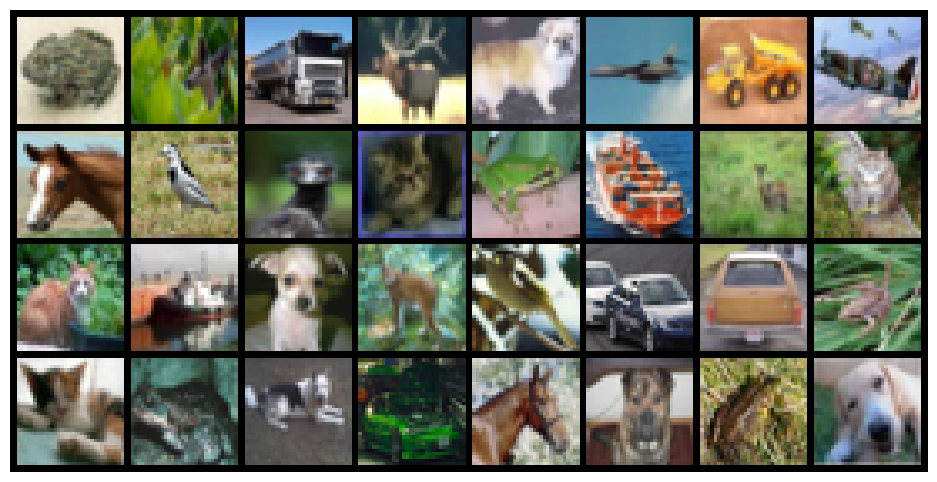

In [14]:
from torchvision.utils import make_grid

for images, _ in test_loader:
    # Create a grid of images
    grid = make_grid(images, nrow=8)

    # Convert from (C, H, W) to (H, W, C)
    grid = grid.permute(1, 2, 0)

    plt.figure(figsize=(12, 6))
    plt.imshow(grid)
    plt.axis("off")
    plt.show()

    break

## d) Data normalization

When loading the data in a), we define 'transform' to just convert the data into Tensor objects. 

Neural network generally benefit from inputs with well-scaled values. 
We can further normaize each RGB channel using its mean and standard deviation:

In [15]:
# Here, the mean and std of each channel is given but in real cases these values must be computed
#normalization: y = (x-mean)/std
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

Reload the data with this transformation and apply the same steps as in b).

Visualize the data as in c):

In [16]:
train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

In [17]:
from sklearn.model_selection import train_test_split
random_state = 42 #for reproductible results

# Split by generating train and val index with train_test_split() 
# Be cautious and keep the proportions of the original dataset
train_indices, val_indices = train_test_split(
    np.arange(len(train_dataset)),
    test_size=0.2,
    random_state=42,
    stratify=np.array(train_dataset.targets)
)

In [18]:
# Convert to Dataset objects
trainset = torch.utils.data.Subset(train_dataset, train_indices)
valset = torch.utils.data.Subset(train_dataset, val_indices)

batch_size = 32 # You can start with 32
train_loader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = torch.utils.data.DataLoader(
    valset,
    batch_size=batch_size,
    shuffle=True
)
test_loader = torch.utils.data.DataLoader(
    test_dataset, 
    batch_size=batch_size,
    shuffle=True
)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..2.1264887].


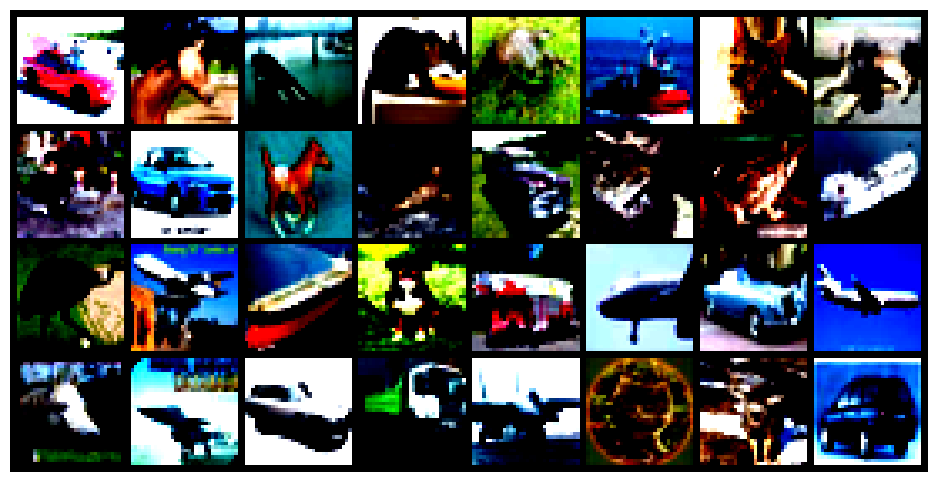

In [19]:
from torchvision.utils import make_grid

for images, _ in test_loader:
    # Create a grid of images
    grid = make_grid(images, nrow=8)

    # Convert from (C, H, W) to (H, W, C)
    grid = grid.permute(1, 2, 0)

    plt.figure(figsize=(12, 6))
    plt.imshow(grid)
    plt.axis("off")
    plt.show()

    break

What is the difference ?

More contrast on images.

# MLP

A MLP is composed of fully connected layers. Fully connected layers expect one-dimensional vector as input, but CIFAR-10 images are 3-dimensional $(3 \times n \times n)$.

So, we first need to flatten each input images and define the input dimension:

In [20]:
input_dim = train_dataset[0][0].shape[0] * train_dataset[0][0].shape[1] * train_dataset[0][0].shape[2]
input_dim

3072

## a) Implementation

Here, we define our model as a class object with properties like layers, activation functions...etc and always a `forward` function that is called for any forward pass through the model.

In the Pytorch documentation, authors describe `nn.Module` as:

"*Base class for all neural network modules. **Your models should also subclass this class.** Modules can also contain other Modules, allowing to nest them in a tree structure.*"

Check this documentation to understand how to design your models using pytorch `nn.Module`: https://pytorch.org/docs/stable/generated/torch.nn.Module.html

We will implement a simple architecture composed of 2 layers. The layers of the model need to follow this order:

input_data $\rightarrow$ Flatten() $\rightarrow$ Linear(input_dim) $\rightarrow$ ReLU() $\rightarrow$ Linear(512, 256) $\rightarrow$ Linear(256, nb_classes)

In [21]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3 * 32 * 32, 512),
            nn.ReLU(),

            nn.Linear(512, 256),
            nn.ReLU(),

            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.network(x)

After creating the model class, we need to declare it and push to device:

In [22]:
model = MLP().to(device)
print(model)

MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)


Calculate the number of parameters of the model:

In [23]:
num_parameters = sum(
    p.numel() for p in model.parameters()
)

print("Number of parameters:", num_parameters)

Number of parameters: 1707274


## b) Loss and optimizer

We consider a multi-class classification problem, so the loss function to use is the cross-entropy:

$$ \mathcal{L}_{\mathrm{CE}} = -\frac{1}{N} \sum_{i=1}^{N} \sum_{j=1}^{C} y_{i,j} \log (p_{i,j}) $$

All standard losses are implemented directly in PyTorch, same for standard optimizers. We just have to declare them.

Note: The cross-entropy loss function implemented in PyTorch expects raw logits outputs from the neural network, so the final layer of the model should not contain a Softmax activation.

In [24]:
# TODO
# Search into Pytorch documentation to declare the cross-entropy loss and the Adam optimizer
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3
)

## c) Training loop

Once we have our DataLoaders, model, loss and optimizer defined, we can train our model.
A typical training loop in PyTorch generally follows:
1. Put the model in training mode
2. Iterate over batches (over DataLoader)
3. Reset the gradients
4. Compute predictions
5. Compute the loss
6. Compute gradients using backpropagation
7. Update the model parameters

Here is an example of training loop:

In [23]:
num_epochs = 10
train_losses = []

for epoch in range(num_epochs):
    # Put the model in training mode
    model.train()

    # runnning loss to track across batches
    running_loss = 0.0

    # Iterate over batches
    for x, y in train_loader:
        x = x.to(device) # data/images
        y = y.to(device) # labels

        # Reset gradients
        optimizer.zero_grad()

        # Compute predictions
        outputs = model(x)

        # Compute loss
        loss = criterion(outputs, y)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        running_loss += loss.item()

    # average loss values
    epoch_loss = running_loss/len(train_loader)
    train_losses.append(epoch_loss)

    print(f'Epoch {epoch+1}/{num_epochs}:\n \t Loss: {epoch_loss}')
    

Epoch 1/10:
 	 Loss: 1.7084923211574554
Epoch 2/10:
 	 Loss: 1.5290293084144593
Epoch 3/10:
 	 Loss: 1.4320925087451934
Epoch 4/10:
 	 Loss: 1.3558569323539733
Epoch 5/10:
 	 Loss: 1.2856694928646089
Epoch 6/10:
 	 Loss: 1.2260628954410553
Epoch 7/10:
 	 Loss: 1.1661050307273866
Epoch 8/10:
 	 Loss: 1.1068957739830017
Epoch 9/10:
 	 Loss: 1.0543006162166595
Epoch 10/10:
 	 Loss: 1.0018773568868637


Implement this training process as a function that you can reuse for any model. 

In [25]:
# TODO
# Training function for one epoch
def train(model, data_loader, optimizer, criterion, device):
    # Put the model in training mode
    model.train()

    # runnning loss to track across batches
    running_loss = 0.0

    # Iterate over batches
    for x, y in train_loader:
        x = x.to(device) # data/images
        y = y.to(device) # labels

        # Reset gradients
        optimizer.zero_grad()

        # Compute predictions
        outputs = model(x)

        # Compute loss
        loss = criterion(outputs, y)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        running_loss += loss.item()

    # average loss values
    epoch_loss = running_loss/len(data_loader)
    return epoch_loss

## d) Evaluation 

The training loop implemented in c) permits to train the model for a number of fixed epoch. However, we only compute the loss using the training set. We also want to evaluate the model using the validation and test sets. 

We then need to turn the model on evaluation mode and deactivate the gradients.

Write a function to evaluate a model that returns the loss value and the accuracy:

In [26]:
def evaluate(model, data_loader, device):

    model.eval()

    correct = 0
    total = 0
    running_loss = 0.0

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            predictions = F.softmax(outputs, dim=1).argmax(dim=1)
            #predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()
            running_loss += loss.item()

    return running_loss/len(data_loader), correct / total

## e) Train the model

We now have all the elements to execute a complete training and evaluation process.

By using the functions that you implemented, train the MLP model for 50 epochs and evaluate it on the test set at the end. 

At each epoch, train the model on the training set and evaluate on the training and validation set.

Plot the loss value and accuracy evolution over the number of epoch for the train and validation sets. Save all the loss, accuracy values of each epoch in a pandas DataFrame to keep a training history.

In [27]:
import pandas as pd

In [29]:
# Declare model 
device = device
model = MLP().to(device)
print(model)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3
)

num_epoch = 50
train_losses = []
train_accs = []
val_losses = []
val_accs = []

# Training loop
for epoch in range(num_epoch):
    # Train
    train_loss = train(model, train_loader, optimizer, criterion, device)
    train_losses.append(train_loss)
    
    # Eval
    _, train_acc = evaluate(model, train_loader, device)
    val_loss, val_acc = evaluate(model, val_loader, device)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(f'Epoch {epoch+1}/{num_epoch}:\n \t Train loss: {train_losses[-1]}\n \t Train accuracy: {train_accs[-1]}\n \t Val loss: {val_losses[-1]}\n \t Val accuracy: {val_accs[-1]}\n')

# Save history 
training_history = pd.DataFrame(columns=['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc'])
training_history['epoch'] = [i for i in range(num_epoch)]
training_history['train_loss'] = train_losses
training_history['train_acc'] = train_accs
training_history['val_loss'] = val_losses
training_history['val_acc'] = val_accs

MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)
Epoch 1/50:
 	 Train loss: 1.7053863373756408
 	 Train accuracy: 0.4566
 	 Val loss: 1.5907982138399117
 	 Val accuracy: 0.4379

Epoch 2/50:
 	 Train loss: 1.5259346502304076
 	 Train accuracy: 0.492825
 	 Val loss: 1.5460201600870005
 	 Val accuracy: 0.4507

Epoch 3/50:
 	 Train loss: 1.4294704296588898
 	 Train accuracy: 0.521425
 	 Val loss: 1.5201106699891747
 	 Val accuracy: 0.4685

Epoch 4/50:
 	 Train loss: 1.3469566524982453
 	 Train accuracy: 0.559825
 	 Val loss: 1.4750995317967937
 	 Val accuracy: 0.4871

Epoch 5/50:
 	 Train loss: 1.2857659596443176
 	 Train accuracy: 0.581275
 	 Val loss: 1.4688124075865212
 	 Val accuracy: 0.4951

Epoch 6/50:
 	 Train loss: 1.220434670639038
 	 Tra

In [30]:
import seaborn as sns

Text(0.5, 1.0, 'Evolution of loss')

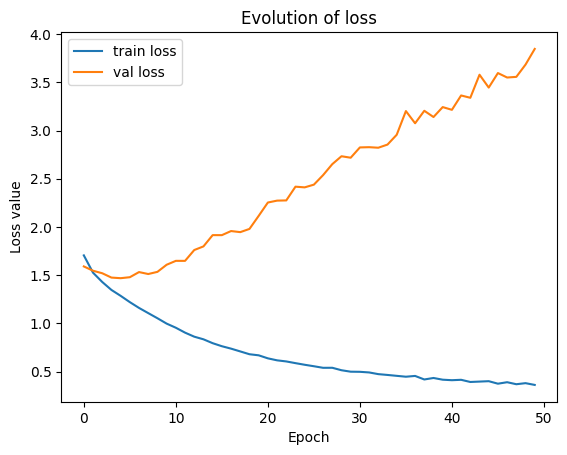

In [31]:
plt.figure()
sns.lineplot(data=training_history, x='epoch', y='train_loss', label='train loss')
sns.lineplot(data=training_history, x='epoch', y='val_loss', label='val loss')
plt.xlabel('Epoch')
plt.ylabel('Loss value')
plt.title('Evolution of loss')

Text(0.5, 1.0, 'Evolution of accuracy')

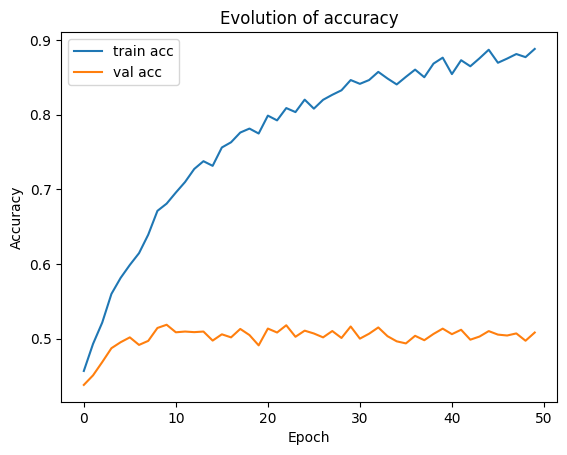

In [32]:
plt.figure()
sns.lineplot(data=training_history, x='epoch', y='train_acc', label='train acc')
sns.lineplot(data=training_history, x='epoch', y='val_acc', label='val acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Evolution of accuracy')

In [37]:
training_history

,epoch,train_loss,train_acc,val_loss,val_acc
0,0,1.707380,0.451100,1.600005,0.4344
1,1,1.526891,0.495850,1.547348,0.4530
2,2,1.428504,0.534700,1.515644,0.4813
3,3,1.358933,0.556175,1.482243,0.4832
4,4,1.284786,0.588850,1.463362,0.5009
5,5,1.218319,0.596025,1.483415,0.4954
6,6,1.166206,0.619175,1.521719,0.4971
7,7,1.100506,0.626725,1.549552,0.4919
8,8,1.054626,0.661550,1.550226,0.5101
9,9,1.003400,0.681300,1.572059,0.5123


In [33]:
test_acc = evaluate(model, test_loader, device)

In [34]:
test_acc

(3.811311853579439, 0.5028)

## Regularization

In [36]:
class MLP_v2(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3 * 32 * 32, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.network(x)

In [37]:
# Declare model 
device = device
model = MLP_v2().to(device)
print(model)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3
)

num_epochs = 50
train_losses = []
train_accs = []
val_losses = []
val_accs = []

# Training loop
for epoch in range(num_epochs):
    # Train
    train_loss = train(model, train_loader, optimizer, criterion, device)
    train_losses.append(train_loss)
    
    # Eval
    _, train_acc = evaluate(model, train_loader, device)
    val_loss, val_acc = evaluate(model, val_loader, device)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(f'Epoch {epoch+1}/{num_epochs}:\n \t Train loss: {train_losses[-1]}\n \t Train accuracy: {train_accs[-1]}\n \t Val loss: {val_losses[-1]}\n \t Val accuracy: {val_accs[-1]}\n')

# Save history 
training_history_regu = pd.DataFrame(columns=['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc'])
training_history_regu['epoch'] = [i for i in range(num_epoch)]
training_history_regu['train_loss'] = train_losses
training_history_regu['train_acc'] = train_accs
training_history_regu['val_loss'] = val_losses
training_history_regu['val_acc'] = val_accs

MLP_v2(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.2, inplace=False)
    (5): Linear(in_features=512, out_features=256, bias=True)
    (6): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=256, out_features=10, bias=True)
  )
)
Epoch 1/50:
 	 Train loss: 1.7057561664581298
 	 Train accuracy: 0.4722
 	 Val loss: 1.5288184098542308
 	 Val accuracy: 0.4535

Epoch 2/50:
 	 Train loss: 1.5267068485736848
 	 Train accuracy: 0.524975
 	 Val loss: 1.4318812011529842
 	 Val accuracy: 0.4902

Epoch 3/50:
 	 Train loss: 1.446836311006546
 	 Train accuracy: 0.552525
 	 Val loss: 1.3853620663999369
 	 Val accuracy: 0.5046

Epoch 4/50:
 	 Train loss: 1.3917405253887176
 	 Trai

Text(0.5, 1.0, 'Evolution of loss')

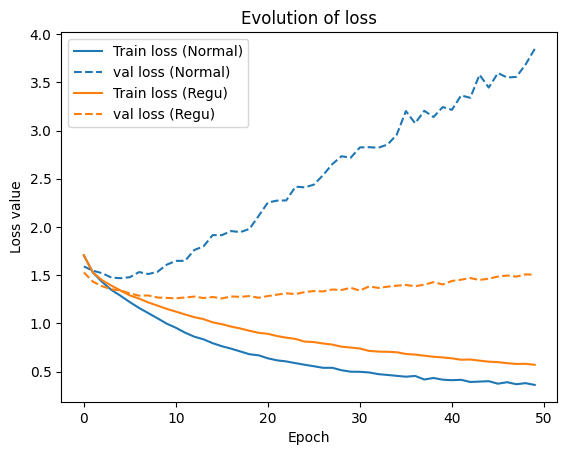

In [38]:
plt.figure()
sns.lineplot(data=training_history, x='epoch', y='train_loss', label='Train loss (Normal)', color='C0', linestyle='-')
sns.lineplot(data=training_history, x='epoch', y='val_loss', label='val loss (Normal)', color='C0', linestyle='--')
sns.lineplot(data=training_history_regu, x='epoch', y='train_loss', label='Train loss (Regu)', color='C1', linestyle='-')
sns.lineplot(data=training_history_regu, x='epoch', y='val_loss', label='val loss (Regu)', color='C1', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Loss value')
plt.title('Evolution of loss')

Text(0.5, 1.0, 'Evolution of accuracy')

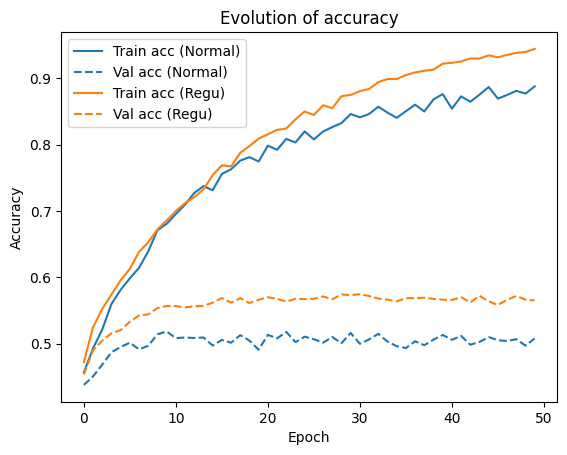

In [39]:
plt.figure()
sns.lineplot(data=training_history, x='epoch', y='train_acc', label='Train acc (Normal)', color='C0', linestyle='-')
sns.lineplot(data=training_history, x='epoch', y='val_acc', label='Val acc (Normal)', color='C0', linestyle='--')
sns.lineplot(data=training_history_regu, x='epoch', y='train_acc', label='Train acc (Regu)', color='C1', linestyle='-')
sns.lineplot(data=training_history_regu, x='epoch', y='val_acc', label='Val acc (Regu)', color='C1', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Evolution of accuracy')

In [40]:
test_acc = evaluate(model, test_loader, device)
test_acc

(1.5008019106075787, 0.5565)

# CNN

The MLP treats an image as a 1-dimensional vector.

However, images have a spatial structure.

For example, neighboring pixels are related to one another,
and local patterns such as edges and textures can be useful
for recognizing objects.

A CNN explicitly exploits this spatial structure through
convolutional layers. There is no need to flatten the input data with this architecture.

## a) Implementation

PyTorch documentation for CNN:
- https://pytorch.org/docs/stable/nn.functional.html
- [Conv2d](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)
- [MaxPool2d](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html)
- [Dropout](https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html)
- [Linear](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html)

We will follow an architecture such as:

input $\rightarrow$ Conv2D(in=3, out=32) $\rightarrow$ ReLU $\rightarrow$ MaxPool2D(2x2) $\rightarrow$ Conv2D (in=32, out=64) $\rightarrow$ ReLU $\rightarrow$ MaxPool2D(2x2) $\rightarrow$ Flatten $\rightarrow$ Linear(128) $\rightarrow$ ReLU $\rightarrow$ Linear(nb_classes)

In [41]:
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=3
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(64 * 6 * 6, 128),
            nn.ReLU(),

            nn.Linear(128, 10)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x

model_cnn = CNN().to(device) # train on GPU if available

Find the number of parameters of the model:

In [42]:
num_parameters = sum(
    p.numel() for p in model_cnn.parameters()
)

print("Number of parameters:", num_parameters)

Number of parameters: 315722


### Understanding the dimension

How do we keep track of the image sizes after convolutions, poolings and padding ?

Pytorch documentation displays the equations to compute the image size.
Check the documentation of each layer!
https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html#torch.nn.Conv2d
https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html#torch.nn.MaxPool2d

Let's perform a safety check below using the equation provided by pytorch:

For one spatial dimension, the ouput size of a convolution is:
$$ D_{\mathrm{out}} = \left\lfloor \dfrac{D_{\mathrm{in}}+2\mathrm{padding}-\mathrm{dilation}*(\mathrm{kernel}-1)-1}{\mathrm{stride}} + 1 \right\rfloor $$

Pooling layers follow the same formula but with different parameters.

Implement a function that will compute the output dimension after convolution and after pooling layer:

In [43]:
# Function to compute size after conv2D layer or maxpooling 2D layer and to compute the value of padding when using padding='same'
def conv_output_dim(input_size, kernel_size, padding=0, stride=1, dilation=1):
    # TODO
    return np.floor((input_size + (2*padding) - (dilation * (kernel_size-1)) - 1) / stride ) + 1

def pool_output_dim(input_size, kernel_size, padding=0, stride=None, dilation=1):
    # TODO
    if stride == None: stride=kernel_size
    return np.floor((input_size + (2*padding) - (dilation * (kernel_size-1)) - 1) / stride) + 1

Use these functions to calculate the spatial dimensions after each operation:

In [44]:
input_dims = 3, 32, 32
# TODO
conv_dim_1 = conv_output_dim(input_dims[1], kernel_size=3)
conv_dim_2 = conv_output_dim(input_dims[2], kernel_size=3)
print(f'Output dimensions after 1st Conv layer: {32, conv_dim_1, conv_dim_2}\n')

pool_dim_1 = pool_output_dim(conv_dim_1, kernel_size=2)
pool_dim_2 = pool_output_dim(conv_dim_2, kernel_size=2)
print(f'Output dimensions after 1st Pooling layer: {32, pool_dim_1, pool_dim_2}\n')

conv_dim_1 = conv_output_dim(pool_dim_1, kernel_size=3)
conv_dim_2 = conv_output_dim(pool_dim_1, kernel_size=3)
print(f'Output dimensions after 2nd Conv layer: {64, conv_dim_1, conv_dim_1}\n')

pool_dim_1 = pool_output_dim(conv_dim_1, kernel_size=2)
pool_dim_2 = pool_output_dim(conv_dim_2, kernel_size=2)
print(f'Output dimensions after 2nd Pooling layer: {64, pool_dim_1, pool_dim_1}\n')

Output dimensions after 1st Conv layer: (32, np.float64(30.0), np.float64(30.0))

Output dimensions after 1st Pooling layer: (32, np.float64(15.0), np.float64(15.0))

Output dimensions after 2nd Conv layer: (64, np.float64(13.0), np.float64(13.0))

Output dimensions after 2nd Pooling layer: (64, np.float64(6.0), np.float64(6.0))



This helps understand more what happen inside our model.

## b) Train the model

Train your CNN model in the same way as the MLP.

You can reuse the training and evaluation function. Do not forget to keep a training history.

In [45]:
# Declare model 
device = device
model_cnn = CNN().to(device)
print(model_cnn)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model_cnn.parameters(),
    lr=1e-3
)

num_epoch = 50
train_losses = []
train_accs = []
val_losses = []
val_accs = []

# Training loop
for epoch in range(num_epoch):
    # Train
    train_loss = train(model_cnn, train_loader, optimizer, criterion, device)
    train_losses.append(train_loss)
    
    # Eval
    _, train_acc = evaluate(model_cnn, train_loader, device)
    val_loss, val_acc = evaluate(model_cnn, val_loader, device)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(f'Epoch {epoch+1}/{num_epoch}:\n \t Train loss: {train_losses[-1]}\n \t Train accuracy: {train_accs[-1]}\n \t Val loss: {val_losses[-1]}\n \t Val accuracy: {val_accs[-1]}\n')

# Save history 
cnn_training_history = pd.DataFrame(columns=['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc'])
cnn_training_history['epoch'] = [i for i in range(num_epoch)]
cnn_training_history['train_loss'] = train_losses
cnn_training_history['train_acc'] = train_accs
cnn_training_history['val_loss'] = val_losses
cnn_training_history['val_acc'] = val_accs

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2304, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Epoch 1/50:
 	 Train loss: 1.3518062039852143
 	 Train accuracy: 0.63385
 	 Val loss: 1.108320389883206
 	 Val accuracy: 0.6063

Epoch 2/50:
 	 Train loss: 0.9902418740987777
 	 Train accuracy: 0.7039
 	 Val loss: 0.9834940576324829
 	 Val accuracy: 0.6592

Epoch 3/50:
 	 Train loss: 0.825849706530571
 	 Train accuracy: 0.767525
 	 Val loss: 0.8904353510647917
 	 Val accuracy: 0.6906

Epoch 4/50:
 	 Train loss: 0.703567989516258

Save the model -> useful later for transfer learning <br>
Help: https://pytorch.org/tutorials/beginner/saving_loading_models.html


In [ ]:
PATH = './cifar_cnn.pth'
torch.save(net.state_dict(), PATH)

In [46]:
test_acc = evaluate(model_cnn, test_loader, device)

In [47]:
test_acc

(4.016890563142185, 0.6757)

In [49]:
class CNN_v2(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(64 * 6 * 6, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.5),

            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


In [51]:
# Declare model 
device = device
model_cnn = CNN_v2().to(device)
print(model_cnn)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model_cnn.parameters(),
    lr=1e-3
)

num_epoch = 50
train_losses = []
train_accs = []
val_losses = []
val_accs = []

# Training loop
for epoch in range(num_epoch):
    # Train
    train_loss = train(model_cnn, train_loader, optimizer, criterion, device)
    train_losses.append(train_loss)
    
    # Eval
    _, train_acc = evaluate(model_cnn, train_loader, device)
    val_loss, val_acc = evaluate(model_cnn, val_loader, device)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(f'Epoch {epoch+1}/{num_epoch}:\n \t Train loss: {train_losses[-1]}\n \t Train accuracy: {train_accs[-1]}\n \t Val loss: {val_losses[-1]}\n \t Val accuracy: {val_accs[-1]}\n')

# Save history 
cnn_training_history_regu = pd.DataFrame(columns=['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc'])
cnn_training_history_regu['epoch'] = [i for i in range(num_epoch)]
cnn_training_history_regu['train_loss'] = train_losses
cnn_training_history_regu['train_acc'] = train_accs
cnn_training_history_regu['val_loss'] = val_losses
cnn_training_history_regu['val_acc'] = val_accs

CNN_v2(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2304, out_features=128, bias=True)
    (2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.5, inplace=False)
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Epoch 1/50:
 	 Train loss: 1.3593286589145661
 	 Train accuracy: 0.6504
 	 Val loss: 1.0529705788761663
 	 Val accuracy: 0

Text(0.5, 1.0, 'Evolution of loss')

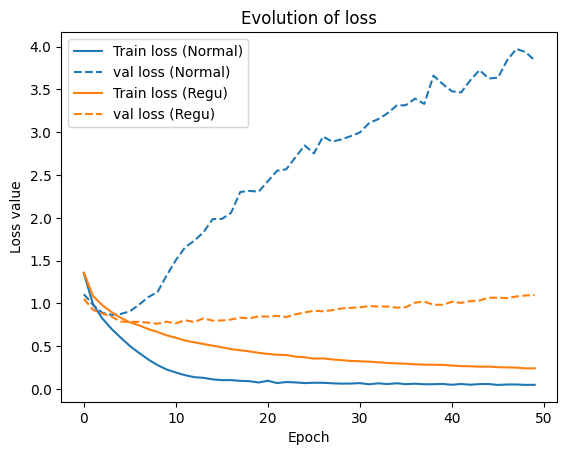

In [52]:
plt.figure()
sns.lineplot(data=cnn_training_history, x='epoch', y='train_loss', label='Train loss (Normal)', color='C0', linestyle='-')
sns.lineplot(data=cnn_training_history, x='epoch', y='val_loss', label='val loss (Normal)', color='C0', linestyle='--')
sns.lineplot(data=cnn_training_history_regu, x='epoch', y='train_loss', label='Train loss (Regu)', color='C1', linestyle='-')
sns.lineplot(data=cnn_training_history_regu, x='epoch', y='val_loss', label='val loss (Regu)', color='C1', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Loss value')
plt.title('Evolution of loss')

Text(0.5, 1.0, 'Evolution of accuracy')

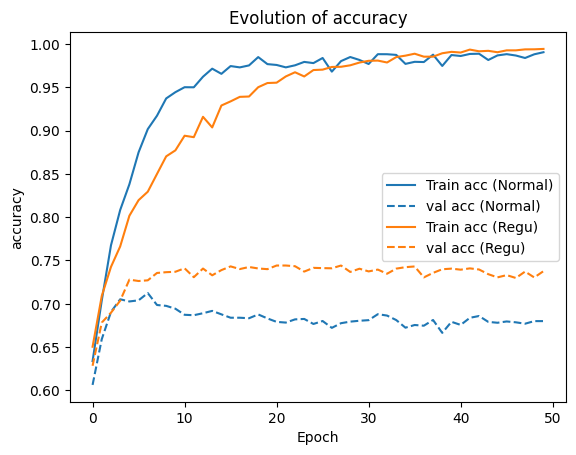

In [53]:
plt.figure()
sns.lineplot(data=cnn_training_history, x='epoch', y='train_acc', label='Train acc (Normal)', color='C0', linestyle='-')
sns.lineplot(data=cnn_training_history, x='epoch', y='val_acc', label='val acc (Normal)', color='C0', linestyle='--')
sns.lineplot(data=cnn_training_history_regu, x='epoch', y='train_acc', label='Train acc (Regu)', color='C1', linestyle='-')
sns.lineplot(data=cnn_training_history_regu, x='epoch', y='val_acc', label='val acc (Regu)', color='C1', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.title('Evolution of accuracy')

# Compare MLP and CNN

Compare the two architectures that you trained:
1) Plot the training curves side by side
2) Compare the number of parameters
3) Final accuracies on test set


<Axes: xlabel='epoch', ylabel='train_loss'>

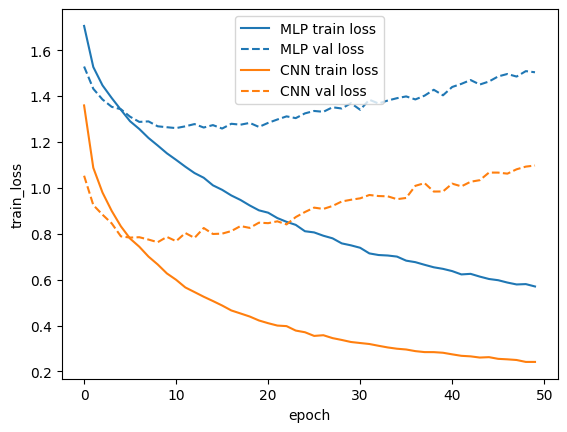

In [55]:
plt.figure()
sns.lineplot(data=training_history_regu, x='epoch', y='train_loss', label='MLP train loss', color='C0')
sns.lineplot(data=training_history_regu, x='epoch', y='val_loss', label='MLP val loss', color='C0', linestyle='--')
sns.lineplot(data=cnn_training_history_regu, x='epoch', y='train_loss', label='CNN train loss', color='C1')
sns.lineplot(data=cnn_training_history_regu, x='epoch', y='val_loss', label='CNN val loss', color='C1', linestyle='--')

<Axes: xlabel='epoch', ylabel='train_acc'>

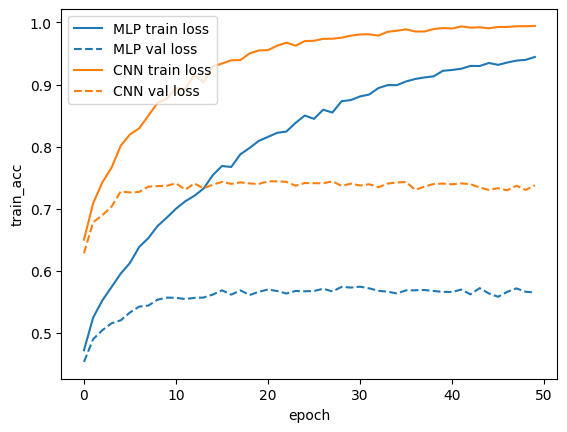

In [56]:
plt.figure()
sns.lineplot(data=training_history_regu, x='epoch', y='train_acc', label='MLP train loss', color='C0')
sns.lineplot(data=training_history_regu, x='epoch', y='val_acc', label='MLP val loss', color='C0', linestyle='--')
sns.lineplot(data=cnn_training_history_regu, x='epoch', y='train_acc', label='CNN train loss', color='C1')
sns.lineplot(data=cnn_training_history_regu, x='epoch', y='val_acc', label='CNN val loss', color='C1', linestyle='--')

In [57]:
mlp_perf = evaluate(model, test_loader, device)
cnn_perf = evaluate(model_cnn, test_loader, device)

In [58]:
print(mlp_perf)
print(cnn_perf)

(1.4999540025433793, 0.5565)
(1.0813799240052129, 0.74)


Questions:
1) Which model performs better ?
2) Which model has more parameters ?
3) How does the CNN exploit spatial structure ? Is it effective ?
4) What information is lost when flatten layer is applied ?

In [3]:
# TODO

# Error analysis

We considered accuracy for the evaluation but this metric does not give precise error estimation.<br>
To see which classes are most frequently confused, we can use confusion matrix. A classification report containing several metrics will also be considered.

In [75]:
import itertools
from sklearn.metrics import confusion_matrix, classification_report

In [76]:
# function to print a confusion matrix given a sklearn confusion matrix object
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues, size=15):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    from http://scikit-learn.org/stable/auto_examples/model_selection/plot_confusion_matrix.html
    :param cm: (numpy matrix) confusion matrix
    :param classes: [str]
    :param normalize: (bool)
    :param title: (str)
    :param cmap: (matplotlib color map)
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(size,size+2))
    im = plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title, size=18, family='serif')
    cb = plt.colorbar(im, fraction=0.046, pad=0.04)
    cb.ax.tick_params(labelsize=14)
    #Set the font type and size of the colorbar
    for l in cb.ax.yaxis.get_ticklabels():
        l.set_family("serif")

    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=90, fontname='serif', size=14)
    plt.yticks(tick_marks, classes, fontname='serif', size=14)

    fmt = '.1f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black",
                 family='serif',
                 size=12)


    plt.ylabel('True label', size=18, fontname='serif')
    plt.xlabel('Predicted label', size=18, fontname='serif')
    plt.tight_layout()
    plt.show()

Compute the confusion matrix of one or both of your models. Normally, you don't have to retrain your models, you only need to use them in evaluation mode. You might want to collect the predictions and labels in two lists.

In [74]:
def get_predictions(model, data_loader, device):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    return np.array(all_labels), np.array(all_predictions)

In [77]:
labels, predictions = get_predictions(
    model_cnn,
    test_loader,
    device
)
cm = confusion_matrix(labels, predictions) # confusion matrix # TODO

In [78]:
LABELS = {
    0 : "airplane",
    1 : "automobile",
    2 : "bird",
    3 : "cat",
    4 : "deer",
    5 : "dog",
    6 : "frog",
    7 : "horse",
    8 : "ship",
    9 : "truck"
}

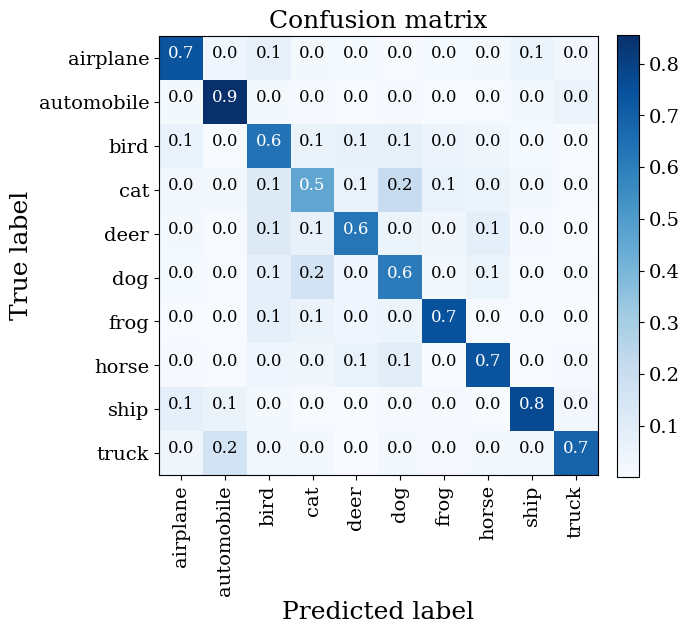

In [79]:
plot_confusion_matrix(cm, LABELS.values(),
                          normalize=True,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues, size=7)

You can do the same for classification report: 

In [83]:
# Report
print(classification_report(labels, predictions, target_names=LABELS.values())) #TODO

              precision    recall  f1-score   support

    airplane       0.73      0.74      0.74      1000
  automobile       0.73      0.86      0.79      1000
        bird       0.54      0.64      0.58      1000
         cat       0.52      0.46      0.49      1000
        deer       0.68      0.63      0.65      1000
         dog       0.55      0.61      0.58      1000
        frog       0.79      0.75      0.77      1000
       horse       0.73      0.74      0.74      1000
        ship       0.83      0.77      0.80      1000
       truck       0.83      0.69      0.75      1000

    accuracy                           0.69     10000
   macro avg       0.69      0.69      0.69     10000
weighted avg       0.69      0.69      0.69     10000



# Extension

## Early-stop

In the previous training functions, the training process was defined for a fixed number of epoch. Usually, we declare an early-stop that will track the loss and stop the training when it is not improving. This tool permits to avoids overfitting.

In [ ]:
# You can build your own callbacks like EarlyStopping for instance:
class EarlyStopper():
    def __init__(self, patience=1, min_delta=0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.min_validation_loss = float('inf')

    def early_stop(self, validation_loss):
        if validation_loss < self.min_validation_loss:
            self.min_validation_loss = validation_loss
            self.counter = 0
        elif validation_loss > (self.min_validation_loss + self.min_delta):
            self.counter += 1
            if self.counter >= self.patience:
                return True
        return False

## Schedulers

Check the documentation for built-in learning rate schedulers:

- https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.LinearLR.html#torch.optim.lr_scheduler.LinearLR

- https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.StepLR.html#torch.optim.lr_scheduler.StepLR

- https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.OneCycleLR.html#torch.optim.lr_scheduler.OneCycleLR

## Data augmentation

For data augmentation, check again the transforms documentation: https://pytorch.org/vision/stable/transforms.html

In [ ]:
# Change transforms to add augmentation
# TODO

## Hyperparameters optimization 

For further optimization, check the Optuna package: https://optuna.readthedocs.io/en/stable/index.html

Read: https://medium.com/pytorch/using-optuna-to-optimize-pytorch-hyperparameters-990607385e36

- You can specify the metric you want to optimize (accuracy, f1_score...etc)
- You write your own objective function
- You specify the search type: grid, random or bayesian for instance.
- You specify the number of trials
- You can retrieve all the search results and best parameters

In [ ]:
import optuna

def objective(trial):
    # TODO
    # objective function to run at each trial.

    # Specify the hyperparameters to search, their type and the value range:
    lr = trial.suggest_loguniform("lr", 1e-5, 1e-1)
    ...

    # Train the model
    model.train()...

    # Must return the metric you want to maximize or minimize.
    return metric

# Create a search study
study = optuna.create_study()
# Run the search
study.optimize(objective, n_trials=..., )
# Check best params
study.best_params

# Build your own

In [68]:
out_dim = conv_output_dim(16, padding=1, kernel_size=3)
pool_out_dim = pool_output_dim(16, kernel_size=2)
out_dim, pool_out_dim

(np.float64(16.0), np.float64(8.0))

In [69]:
class CNN_best(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 64, kernel_size=3, padding='same'),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding='same'),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.2),

            nn.Conv2d(64, 128, kernel_size=3, padding='same'),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding='same'),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(128 * 8 * 8, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(p=0.5),

            nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


In [70]:
# Declare model 
device = device
model_cnn = CNN_best().to(device)
print(model_cnn)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model_cnn.parameters(),
    lr=1e-3
)

num_epoch = 50
train_losses = []
train_accs = []
val_losses = []
val_accs = []

# Training loop
for epoch in range(num_epoch):
    # Train
    train_loss = train(model_cnn, train_loader, optimizer, criterion, device)
    train_losses.append(train_loss)
    
    # Eval
    _, train_acc = evaluate(model_cnn, train_loader, device)
    val_loss, val_acc = evaluate(model_cnn, val_loader, device)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(f'Epoch {epoch+1}/{num_epoch}:\n \t Train loss: {train_losses[-1]}\n \t Train accuracy: {train_accs[-1]}\n \t Val loss: {val_losses[-1]}\n \t Val accuracy: {val_accs[-1]}\n')

# Save history 
cnn_training_history_best = pd.DataFrame(columns=['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc'])
cnn_training_history_best['epoch'] = [i for i in range(num_epoch)]
cnn_training_history_best['train_loss'] = train_losses
cnn_training_history_best['train_acc'] = train_accs
cnn_training_history_best['val_loss'] = val_losses
cnn_training_history_best['val_acc'] = val_accs

CNN_best(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.2, inplace=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (12): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): Dropout(p=0.2, inplace=Fal

<Axes: xlabel='epoch', ylabel='train_loss'>

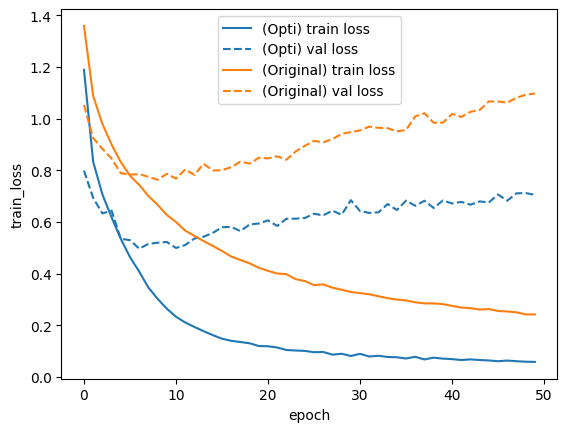

In [71]:
plt.figure()
sns.lineplot(data=cnn_training_history_best, x='epoch', y='train_loss', label='(Opti) train loss', color='C0')
sns.lineplot(data=cnn_training_history_best, x='epoch', y='val_loss', label='(Opti) val loss', color='C0', linestyle='--')
sns.lineplot(data=cnn_training_history_regu, x='epoch', y='train_loss', label='(Original) train loss', color='C1')
sns.lineplot(data=cnn_training_history_regu, x='epoch', y='val_loss', label='(Original) val loss', color='C1', linestyle='--')

<Axes: xlabel='epoch', ylabel='train_acc'>

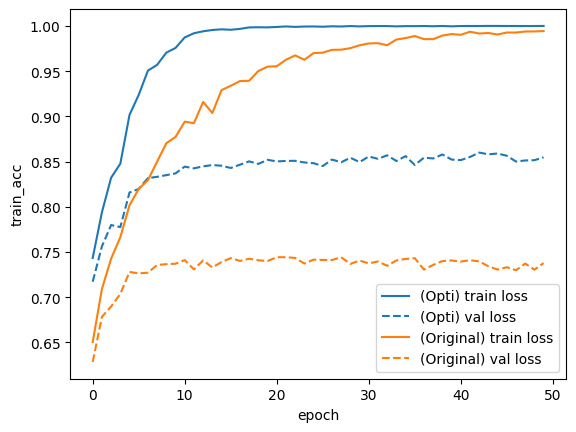

In [72]:
plt.figure()
sns.lineplot(data=cnn_training_history_best, x='epoch', y='train_acc', label='(Opti) train loss', color='C0')
sns.lineplot(data=cnn_training_history_best, x='epoch', y='val_acc', label='(Opti) val loss', color='C0', linestyle='--')
sns.lineplot(data=cnn_training_history_regu, x='epoch', y='train_acc', label='(Original) train loss', color='C1')
sns.lineplot(data=cnn_training_history_regu, x='epoch', y='val_acc', label='(Original) val loss', color='C1', linestyle='--')

In [73]:
cnn_perf_opti = evaluate(model_cnn, test_loader, device)

In [74]:
print(f'Performance CNN original: {cnn_perf}')
print(f'Performance CNN improved: {cnn_perf_opti}')

Performance CNN original: (1.0813799240052129, 0.74)
Performance CNN improved: (0.7189086571978495, 0.8471)
